data provided are of shape (N,1), not (N,).

**1.** Load this file (`np.load`) and complete a quick exploration of the data. How many modes do you think you see?

2950


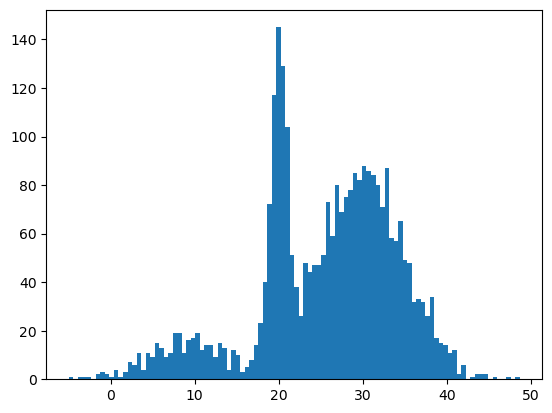

In [19]:
#!pip install scikit-learn

import numpy as np 
from matplotlib import pyplot as plt 
from sklearn.mixture import GaussianMixture
import warnings

warnings.filterwarnings('ignore', category=UserWarning)


file = np.load('C:/Users/user/astrostatistics_bicocca_2026/solutions/formationchannels.npy')

print(len(file))
plt.hist(file, bins=100)

plt.show()

**2.** We'll use `sklearn.mixture.GaussianMixture`. You first need to define the model (instance of a class), and then train it on the data using the `fit` method (the data provided are already in the right numpy format!). This will output the trained model, which has various attributes.


<>:13: SyntaxWarning: invalid escape sequence '\o'
<>:13: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_23736\669980394.py:13: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('Black hole mass [$M_\odot$]')


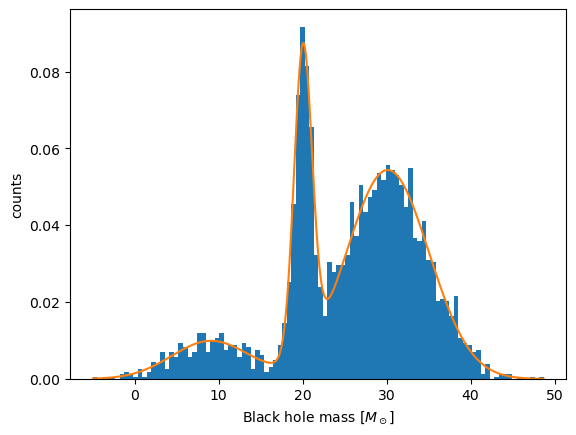

20083.505536921635 True


In [20]:
gm = GaussianMixture(n_components=3, random_state=42).fit(file)

#reshape data bc scikit-learn wants always 2d arrays -1 tells numpy to choose the lines based on n of elements, 1 force him to put all elements in one column
x_plot = np.linspace(file.min(),file.max(), 1000).reshape(-1,1)

log_prob = gm.score_samples(x_plot)
pdf = np.exp(log_prob)



plt.hist(file, bins=100, density=True)
plt.plot(x_plot,pdf)
plt.xlabel('Black hole mass [$M_\odot$]')
plt.ylabel('counts')
plt.show()

print(gm.aic(file),gm.converged_)


**3.** Complete the fit 10 times with $N=1,...,10$ Gaussians.

**4.** For each of these fits, compute the AIC (easy! It's an attribute of the trained model!). Plot $N$ vs AIC: which model is preferred?

AIC minimo per N = 3


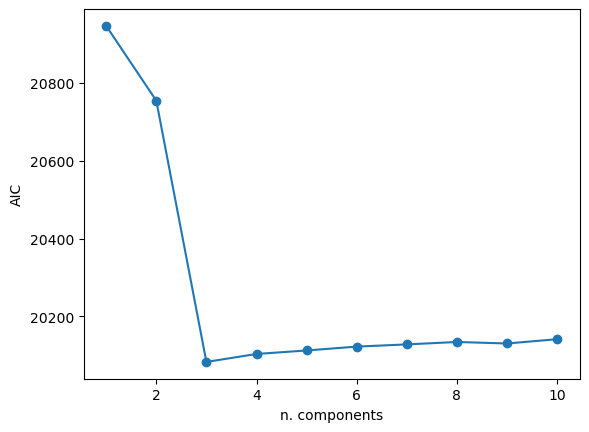

In [21]:
aic_values = []
models = []

n_components_range = range(1,11)

for n in range(1,11):
    M_gm = GaussianMixture(n_components=n).fit(file)

    models.append(M_gm)
    aic_values.append(M_gm.aic(file))

best = np.argmin(aic_values)
print('AIC minimo per N =', n_components_range[best])

plt.plot(n_components_range,aic_values)
plt.scatter(n_components_range, aic_values)
plt.xlabel('n. components')
plt.ylabel('AIC')
plt.show()

**5.** Plot the preferred solution on top of the input data. You should get a very nice fit!

<>:5: SyntaxWarning: invalid escape sequence '\o'
<>:5: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_23736\3107649163.py:5: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('Black hole mass [$M_\odot$]')


Text(0, 0.5, 'counts')

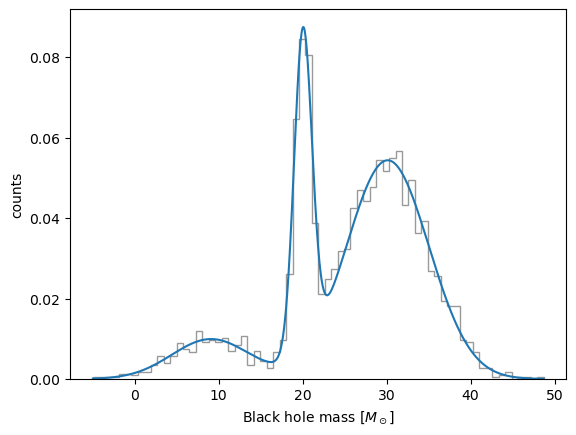

In [22]:
M_best = models[best]
pdf = np.exp(M_best.score_samples(x_plot))
plt.hist(file, bins=70, density=True, histtype='step', color='k', alpha=0.4)
plt.plot(x_plot, pdf)
plt.xlabel('Black hole mass [$M_\odot$]')
plt.ylabel('counts')

#### [Optional tasks, not examinable] Class labels or "responsibilities"

Class labels are a very interesting by product of a mixture analysis. What is the probability that a given gravitational-wave event comes from a given channel? This is called "responsiblity" (i.e. which mode is most likely to be responsible for that piece of data). 

**6.** Understand (i.e. plot) which Gaussian mode corresponds to which part of the input dataset. 

*Hint:* Useful methods here are `score_samples` and `predict_proba`.

[4.21833189e-009 2.10530836e-116 9.99999996e-001]


<>:9: SyntaxWarning: invalid escape sequence '\o'
<>:9: SyntaxWarning: invalid escape sequence '\o'
C:\Users\user\AppData\Local\Temp\ipykernel_23736\3536890102.py:9: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('mass [$M_\odot$]')


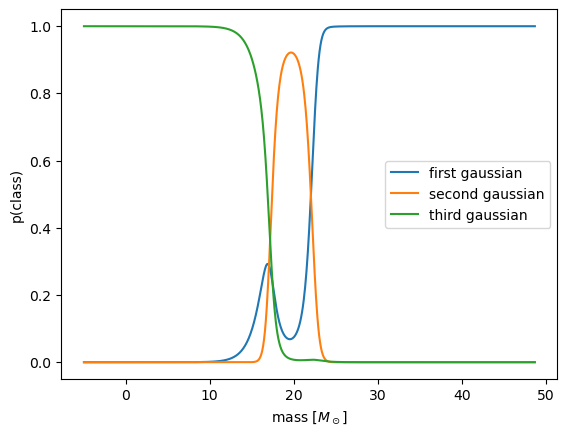

In [23]:
responsability = gm.predict_proba(x_plot)

print(responsability[1])

plt.plot(x_plot, responsability[:,0], label="first gaussian")
plt.plot(x_plot, responsability[:,1], label="second gaussian")
plt.plot(x_plot, responsability[:,2], label="third gaussian")

plt.xlabel('mass [$M_\odot$]')
plt.ylabel('p(class)')
plt.legend()
plt.show()